First five rows:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2  

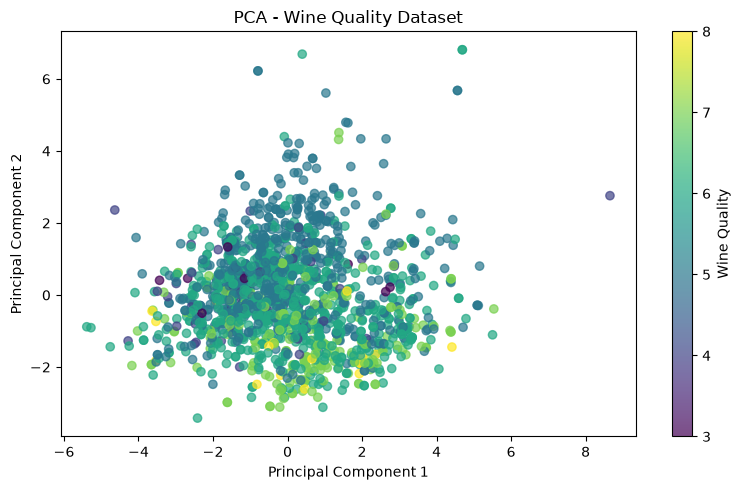

In [15]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

# Step 1: Load the dataset
file_path = r"C:\Users\user\Downloads\archive (15)\winequality-red.csv"
df = pd.read_csv(file_path, sep=None, engine="python")

# Step 2: Clean column names
df.columns = df.columns.str.strip().str.replace("\ufeff", "", regex=False)

# Step 3: Display dataset information
print("First five rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

# Step 4: Separate features and target
X = df.drop(columns=["quality"])
y = df["quality"]

# Step 5: Min-Max Normalization
normalizer = MinMaxScaler()
X_normalized = normalizer.fit_transform(X)

print("\nNormalized data (first 5 rows):")
print(pd.DataFrame(X_normalized, columns=X.columns).head().round(3))

# Step 6: Standardization
standardizer = StandardScaler()
X_standardized = standardizer.fit_transform(X)

print("\nStandardized data (first 5 rows):")
print(pd.DataFrame(X_standardized, columns=X.columns).head().round(3))

# Step 7: Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_standardized)

print("\nPCA output (first 5 rows):")
print(pd.DataFrame(X_pca, columns=["PC1", "PC2"]).head().round(3))

# Step 8: Display feature reduction
print("\nOriginal number of features:", X.shape[1])
print("Reduced number of features:", X_pca.shape[1])

# Step 9: Display explained variance
print("\nVariance retained by each component:")
print(pca.explained_variance_ratio_.round(4))

print(
    "Total variance retained:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

# Step 10: Visualize PCA results
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Wine Quality Dataset")
plt.colorbar(label="Wine Quality")
plt.tight_layout()
plt.show()
